In [1]:
import numpy as np, tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

RNG = 42
np.random.seed(RNG); tf.random.set_seed(RNG)

# Reads from the local ~/.keras/datasets cache pre-seeded in this lab — NO network.
(x_train_full, y_train_full), (x_test_full, y_test_full) = keras.datasets.cifar10.load_data()

CLASSES = ["airplane","automobile","bird","cat","deer","dog",
           "frog","horse","ship","truck"]

def subset(x, y, per_class):
    y = y.ravel()
    idx = np.hstack([np.random.RandomState(RNG).choice(np.where(y==c)[0], per_class, replace=False)
                     for c in range(10)])
    np.random.RandomState(RNG).shuffle(idx)
    return x[idx].astype("float32")/255.0, y[idx].astype("int32")

# small, balanced subset keeps CPU training to minutes
x_train, y_train = subset(x_train_full, y_train_full, 500)   # 5000 imgs
x_test,  y_test  = subset(x_test_full,  y_test_full,  100)   # 1000 imgs
print(x_train.shape, x_test.shape, "range", x_train.min(), x_train.max())

I0000 00:00:1794809443.420973   21871 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794809443.483898   21871 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794809444.978499   21871 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2029s 12us/step
(5000, 32, 32, 3) (1000, 32, 32, 3) range 0.0 1.0


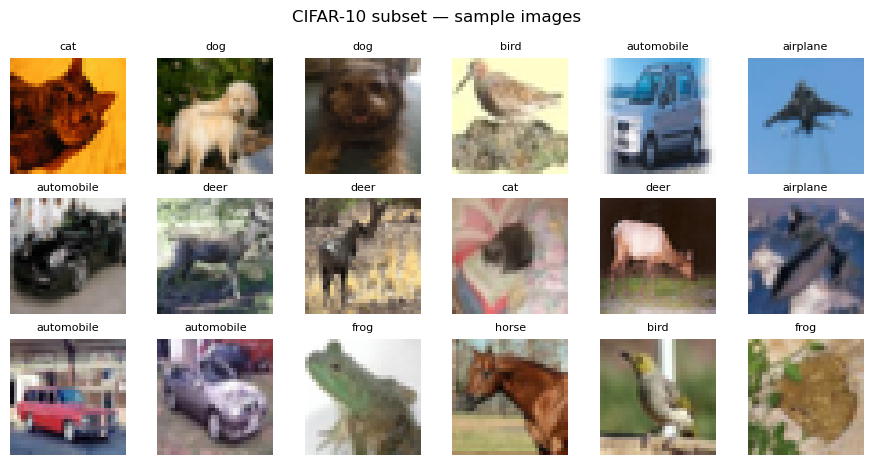

airplane     500
automobile   500
bird         500
cat          500
deer         500
dog          500
frog         500
horse        500
ship         500
truck        500


In [2]:
fig, axes = plt.subplots(3, 6, figsize=(9, 4.7))
for ax, i in zip(axes.ravel(), range(18)):
    ax.imshow(x_train[i]); ax.set_title(CLASSES[y_train[i]], fontsize=8)
    ax.axis("off")
plt.suptitle("CIFAR-10 subset — sample images"); plt.tight_layout(); plt.show()

counts = np.bincount(y_train, minlength=10)
for c, n in enumerate(counts):
    print(f"{CLASSES[c]:12s} {n}")

In [3]:
def make_baseline_cnn():
    m = keras.Sequential([
        keras.Input((32,32,3)),
        layers.Conv2D(32,3,padding="same",activation="relu"), layers.BatchNormalization(),
        layers.MaxPooling2D(),
        layers.Conv2D(64,3,padding="same",activation="relu"), layers.BatchNormalization(),
        layers.MaxPooling2D(),
        layers.Conv2D(128,3,padding="same",activation="relu"), layers.BatchNormalization(),
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.3),
        layers.Dense(10, activation="softmax"),
    ])
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

baseline = make_baseline_cnn()
es = keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=4,
                                   restore_best_weights=True)
hist_base = baseline.fit(x_train, y_train, validation_split=0.2,
                         epochs=25, batch_size=64, callbacks=[es], verbose=2)
base_test = baseline.evaluate(x_test, y_test, verbose=0)[1]
print(f"\nBASELINE test accuracy = {base_test:.3f}")

W0000 00:00:1794811479.924323   21871 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
I0000 00:00:1794811479.925558   21871 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3072 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:1c.0, compute capability: 7.5


Epoch 1/25


I0000 00:00:1794811482.729999   27150 service.cc:153] XLA service 0x7f76e4037310 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794811482.730022   27150 service.cc:161]   StreamExecutor [0]: Tesla T4, Compute Capability 7.5 (Driver: 13.3.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.23.2)
I0000 00:00:1794811482.818454   27150 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1794811483.168028   27150 cuda_dnn.cc:461] Loaded cuDNN version 92302
I0000 00:00:1794811483.255444   27150 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_3044__.49
I0000 00:00:1794811488.612876   27150 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
I0000 00:00:1794811489.289667   27152 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_3044__.49


63/63 - 15s - 233ms/step - accuracy: 0.3205 - loss: 1.8446 - val_accuracy: 0.0950 - val_loss: 2.4082
Epoch 2/25
63/63 - 0s - 7ms/step - accuracy: 0.4430 - loss: 1.5610 - val_accuracy: 0.0950 - val_loss: 3.2019
Epoch 3/25
63/63 - 0s - 6ms/step - accuracy: 0.4857 - loss: 1.4269 - val_accuracy: 0.1000 - val_loss: 4.2542
Epoch 4/25
63/63 - 0s - 6ms/step - accuracy: 0.5228 - loss: 1.3326 - val_accuracy: 0.1440 - val_loss: 5.0556
Epoch 5/25
63/63 - 0s - 6ms/step - accuracy: 0.5575 - loss: 1.2495 - val_accuracy: 0.1630 - val_loss: 4.8188
Epoch 6/25
63/63 - 0s - 6ms/step - accuracy: 0.5835 - loss: 1.1764 - val_accuracy: 0.1750 - val_loss: 4.2513
Epoch 7/25
63/63 - 0s - 6ms/step - accuracy: 0.6120 - loss: 1.1170 - val_accuracy: 0.2960 - val_loss: 2.4700
Epoch 8/25
63/63 - 0s - 7ms/step - accuracy: 0.6415 - loss: 1.0499 - val_accuracy: 0.2570 - val_loss: 2.6113
Epoch 9/25
63/63 - 0s - 6ms/step - accuracy: 0.6630 - loss: 1.0076 - val_accuracy: 0.3110 - val_loss: 2.7209
Epoch 10/25
63/63 - 0s - 6m

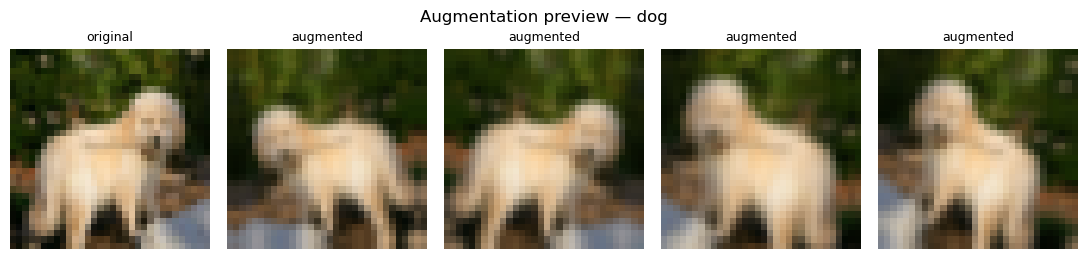

In [4]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.06),
    layers.RandomZoom(0.1),
], name="augment")

img = x_train[1][None, ...]
fig, axes = plt.subplots(1, 5, figsize=(11, 2.6))
axes[0].imshow(img[0]); axes[0].set_title("original", fontsize=9); axes[0].axis("off")
for ax in axes[1:]:
    ax.imshow(np.clip(data_augmentation(img, training=True)[0], 0, 1))
    ax.set_title("augmented", fontsize=9); ax.axis("off")
plt.suptitle(f"Augmentation preview — {CLASSES[y_train[1]]}"); plt.tight_layout(); plt.show()

In [5]:
IMG = 96
base = keras.applications.MobileNetV2(input_shape=(IMG,IMG,3),
                                      include_top=False, weights="imagenet")
base.trainable = False   # freeze — feature extraction only

inputs = keras.Input((32,32,3))
x = data_augmentation(inputs)
x = layers.Resizing(IMG, IMG)(x)
x = layers.Rescaling(255.0)(x)                                   # [0,1] -> [0,255]
x = keras.applications.mobilenet_v2.preprocess_input(x)         # -> [-1,1]
x = base(x, training=False)                                     # frozen backbone
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation="softmax")(x)
tl_model = keras.Model(inputs, outputs)
tl_model.compile(optimizer=keras.optimizers.Adam(1e-3),
                 loss="sparse_categorical_crossentropy", metrics=["accuracy"])
print(f"trainable params (head only): {sum(np.prod(w.shape) for w in tl_model.trainable_weights):,}")

ckpt = keras.callbacks.ModelCheckpoint("day20_best.keras", monitor="val_accuracy",
                                       save_best_only=True)
es2  = keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3,
                                     restore_best_weights=True)
hist_fe = tl_model.fit(x_train, y_train, validation_split=0.2,
                       epochs=8, batch_size=64, callbacks=[es2, ckpt], verbose=2)
fe_test = tl_model.evaluate(x_test, y_test, verbose=0)[1]
print(f"\nFEATURE-EXTRACTION test accuracy = {fe_test:.3f}")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
trainable params (head only): 12,810
Epoch 1/8
63/63 - 10s - 164ms/step - accuracy: 0.3742 - loss: 1.9503 - val_accuracy: 0.6920 - val_loss: 0.9063
Epoch 2/8
63/63 - 2s - 32ms/step - accuracy: 0.5820 - loss: 1.2405 - val_accuracy: 0.7650 - val_loss: 0.7116
Epoch 3/8
63/63 - 2s - 33ms/step - accuracy: 0.6465 - loss: 1.0353 - val_accuracy: 0.7850 - val_loss: 0.6402
Epoch 4/8
63/63 - 2s - 32ms/step - accuracy: 0.6693 - loss: 0.9597 - val_accuracy: 0.7920 - val_loss: 0.6164
Epoch 5/8
63/63 - 2s - 33ms/step - accuracy: 0.6967 - loss: 0.8761 - val_accuracy: 0.8070 - val_loss: 0.5822
Epoch 6/8
63/63 - 2s - 33ms/step - accuracy: 0.7150 - loss: 0.8327 - val_accuracy: 0.8110 - val_loss: 0.5864
Epoch 7/8
63/63 - 2s - 25ms/step - accuracy: 0.7130 - loss: 0.8259 - val_accuracy: 0.8110 - val_loss: 0.5636
Epoch 8/8
63/63 - 2s - 33ms/step - accuracy: 0.7362 - loss: 0.7756 - val_accuracy: 0.8220 - val_loss: 0.5513

FEATURE-EXTRACTION test accuracy = 0.80

In [6]:
base.trainable = True
for layer in base.layers[:-30]:      # keep the lower, generic layers frozen
    layer.trainable = False

tl_model.compile(optimizer=keras.optimizers.Adam(1e-5),   # 100x smaller LR
                 loss="sparse_categorical_crossentropy", metrics=["accuracy"])

es3 = keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3,
                                    restore_best_weights=True)
hist_ft = tl_model.fit(x_train, y_train, validation_split=0.2,
                       epochs=6, batch_size=64, callbacks=[es3, ckpt], verbose=2)
ft_test = tl_model.evaluate(x_test, y_test, verbose=0)[1]
print(f"\nFINE-TUNED test accuracy = {ft_test:.3f}")
print(f"baseline={base_test:.3f}  feat-extract={fe_test:.3f}  fine-tuned={ft_test:.3f}")

Epoch 1/6
63/63 - 13s - 204ms/step - accuracy: 0.5975 - loss: 1.2163 - val_accuracy: 0.8220 - val_loss: 0.5587
Epoch 2/6
63/63 - 2s - 40ms/step - accuracy: 0.6410 - loss: 1.0416 - val_accuracy: 0.8220 - val_loss: 0.5793
Epoch 3/6
63/63 - 3s - 40ms/step - accuracy: 0.6773 - loss: 0.9288 - val_accuracy: 0.8140 - val_loss: 0.5952
Epoch 4/6
63/63 - 2s - 40ms/step - accuracy: 0.7015 - loss: 0.8866 - val_accuracy: 0.8120 - val_loss: 0.6018

FINE-TUNED test accuracy = 0.806
baseline=0.510  feat-extract=0.802  fine-tuned=0.806


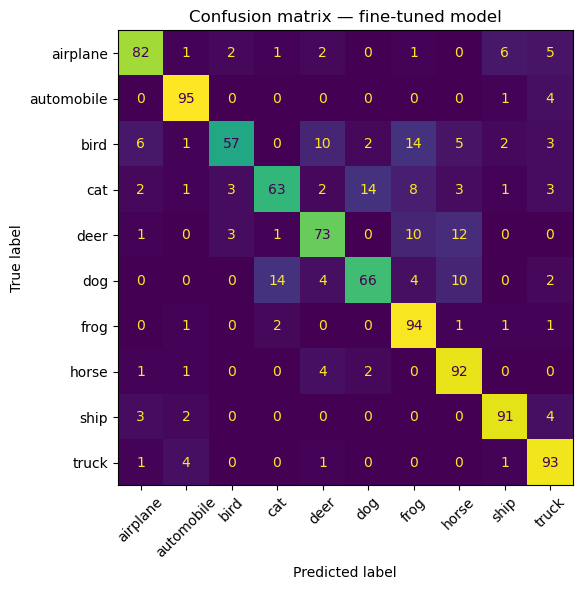

              precision    recall  f1-score   support

    airplane      0.854     0.820     0.837       100
  automobile      0.896     0.950     0.922       100
        bird      0.877     0.570     0.691       100
         cat      0.778     0.630     0.696       100
        deer      0.760     0.730     0.745       100
         dog      0.786     0.660     0.717       100
        frog      0.718     0.940     0.814       100
       horse      0.748     0.920     0.825       100
        ship      0.883     0.910     0.897       100
       truck      0.809     0.930     0.865       100

    accuracy                          0.806      1000
   macro avg      0.811     0.806     0.801      1000
weighted avg      0.811     0.806     0.801      1000



In [7]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

y_prob = tl_model.predict(x_test, verbose=0)
y_pred = y_prob.argmax(axis=1)

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(6.5, 6))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title("Confusion matrix — fine-tuned model"); plt.tight_layout(); plt.show()

print(classification_report(y_test, y_pred, target_names=CLASSES, digits=3))

In [12]:
tl_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augment (Sequential)            │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,349,216 (20.41 MB)

 Trainable params: 1,539,210 (5.87 MB)

 Non-trainable params: 731,584 (2.79 MB)

 Optimizer params: 3,078,422 (11.74 MB)

IndexError: list index out of range

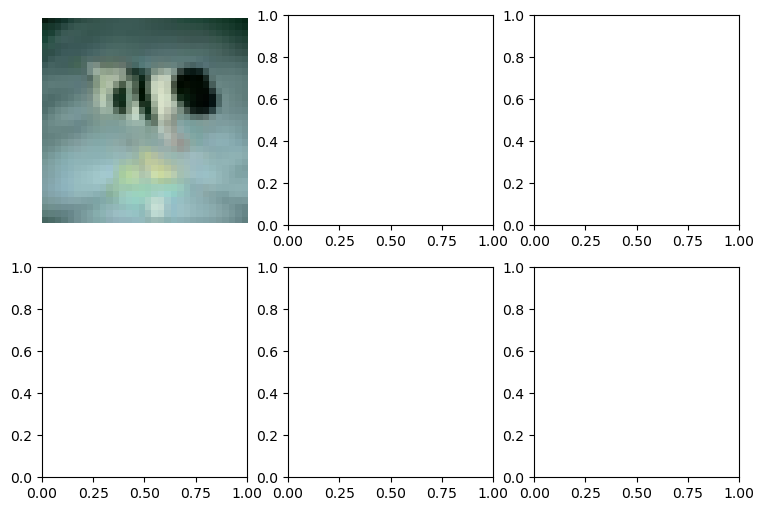

In [19]:
x = tl_model.input
for layer in tl_model.layers[1:]:
    if layer == base:
        break
    x = layer(x)

feature_output = base(x)
y = feature_output

for layer in tl_model.layers[base_index+1:]:
    y = layer(y)

grad_model = keras.Model(
    inputs = tl_model.input,
    outputs = [feature_output, y]
)

def gradcam(img_1, pred_index=None):
    arr = img_1[None, ...]
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(arr)
        preds = tf.reshape(preds,(tf.shape(preds)[0],-1))
        pred_index = tf.argmax(preds[0])
        channel = preds[0, pred_index]
    grads = tape.gradient(channel, conv_out)
    weights = tf.reduce_mean(grads, axis=(0,1,2))
    cam = tf.maximum(tf.reduce_sum(conv_out[0] * weights, axis=-1), 0)
    cam = (cam / (tf.reduce_max(cam) + 1e-8)).numpy()
    return cam, int(pred_index.numpy())

correct = np.where(y_pred == y_test)[0]
show = correct[:3]
fig, axes = plt.subplots(2, 3, figsize=(9, 6))
for col, i in enumerate(show):
    cam, pidx = gradcam(x_test[i])
    cam_up = tf.image.resize(cam[..., None], (32,32)).numpy().squeeze()
    axes[0,col].imshow(x_test[i]); axes[0,col].axis("off")
    axes[0,col].set_title(f"pred: {CLASSES[pidx]}", fontsize=9)
    axes[1,col].imshow(x_test[i]); axes[1,col].imshow(cam_up, cmap="jet", alpha=0.45)
    axes[1,col].axis("off"); axes[1,col].set_title("Grad-CAM", fontsize=9)
plt.suptitle("Where the model looks"); plt.tight_layout(); plt.show()

In [ ]:
print("=== RESULTS SUMMARY ===")
print(f"{'approach':22s}{'test acc':>10s}")
for name, acc in [("Baseline CNN (scratch)", base_test),
                  ("Transfer: feat-extract", fe_test),
                  ("Transfer: fine-tuned",  ft_test)]:
    print(f"{name:22s}{acc:10.3f}")
print(f"\nabsolute lift (fine-tuned - baseline) = {ft_test - base_test:+.3f}")

reflection = """
TODO — replace with 4-6 sentences of your own:
1. How much did transfer learning beat the from-scratch baseline, and why?
2. What did feature-extraction vs fine-tuning each contribute?
3. Which classes were hardest (from the confusion matrix) and does that
   match the Grad-CAM evidence of where the model looks?
4. One thing you'd try next to push accuracy higher (more data / more
   unfrozen layers / stronger augmentation / different backbone).
"""
print(reflection)

# save the finished notebook state artifact
tl_model.save("day20_best.keras")
print("Saved best model -> day20_best.keras")